# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Nazwar Fakhrurrozy | 5054251040 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [139]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, Birch
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [140]:
df = pd.read_csv("Mall_Customers.csv")

print("5 baris pertama:")
display(df.head())

print("Jumlah baris dan kolom:", df.shape)

print("\nTipe data:")
display(df.dtypes)

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nJumlah missing value:")
display(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

5 baris pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris dan kolom: (200, 5)

Tipe data:


CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0



Jumlah missing value:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Jumlah baris duplikat: 0


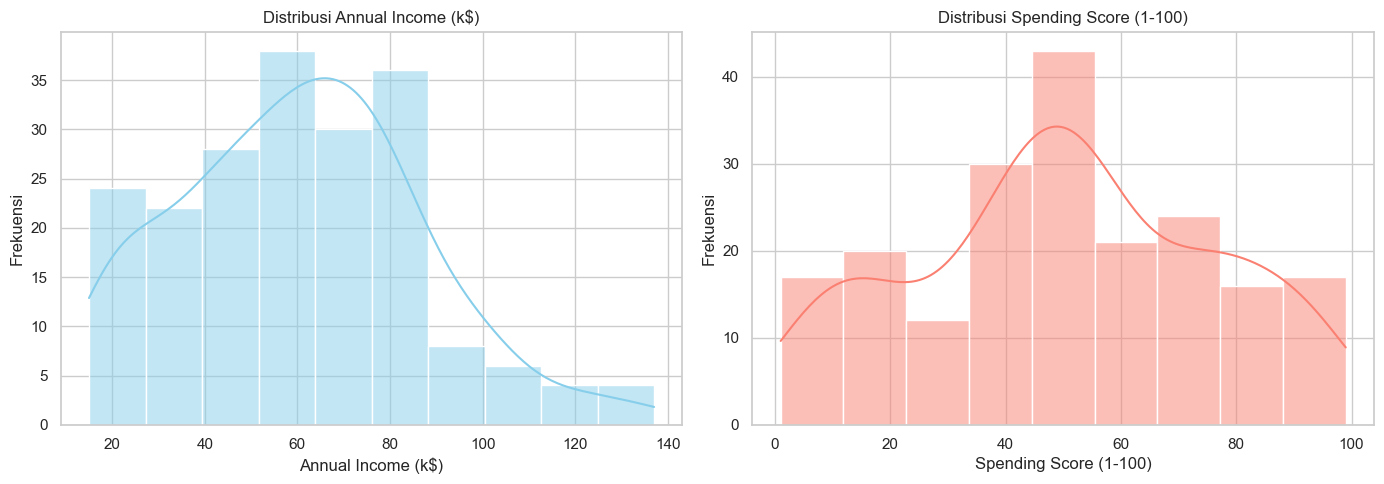

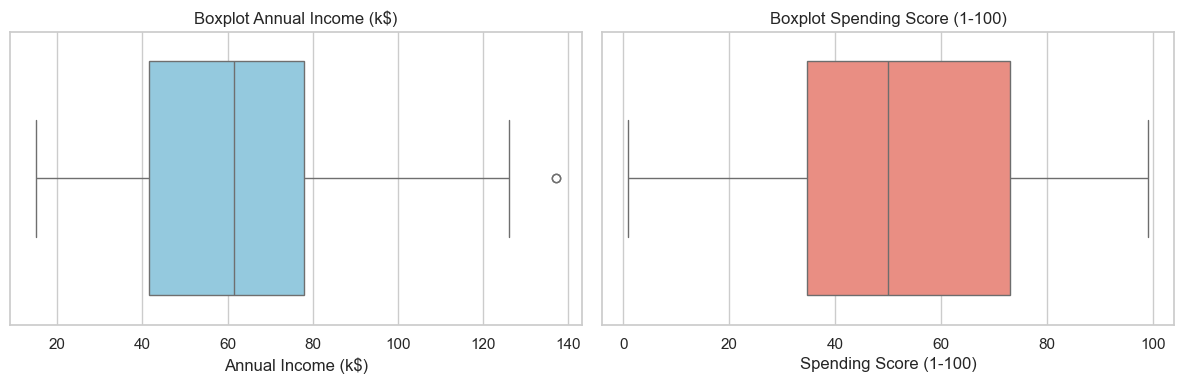

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="Annual Income (k$)", kde=True, ax=axes[0], color="skyblue"
)
axes[0].set_title("Distribusi Annual Income (k$)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Frekuensi")

sns.histplot(
    data=df, x="Spending Score (1-100)", kde=True, ax=axes[1], color="salmon"
)
axes[1].set_title("Distribusi Spending Score (1-100)")
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Annual Income (k$)", ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot Annual Income (k$)")

sns.boxplot(data=df, x="Spending Score (1-100)", ax=axes[1], color="salmon")
axes[1].set_title("Boxplot Spending Score (1-100)")

plt.tight_layout()
plt.show()

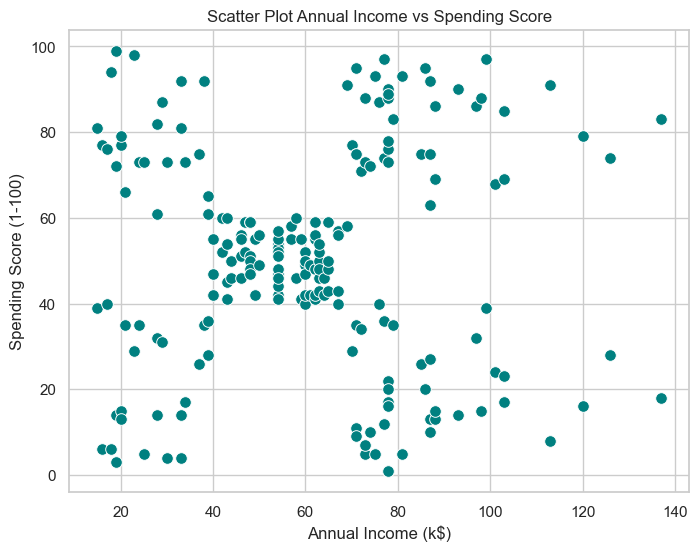

In [142]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=70,
    color="teal",
)
plt.title("Scatter Plot Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

1. Dataset tidak memiliki missing value sama sekali dan tidak ada baris duplikat (0 duplikat)

2. - Annual Income (k$): Nilai minimum 15k, maksimum 137k, dengan median 61.5k dan rata-rata 60.56k. Distribusi relatif simetris dengan sedikit outlier pada nilai di atas 130k
   - Spending Score (1-100): Nilai minimum 1, maksimum 99, dengan median 50.0 dan rata-rata 50.20. Distribusi tersebar merata dari skor rendah hingga tinggi tanpa outlier

3. Pada scatter plot antara Annual Income dan Spending Score, terlihat jelas adanya 5 kelompok atau pola cluster yang terpisah secara visual:
   - Pendapatan rendah, skor pengeluaran rendah
   - Pendapatan rendah, skor pengeluaran tinggi
   - Pendapatan sedang, skor pengeluaran sedang
   - Pendapatan tinggi, skor pengeluaran rendah
   - Pendapatan tinggi, skor pengeluaran tinggi

# 2. Preprocessing

In [143]:
df = df.dropna().drop_duplicates()

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

print("Ukuran DataFrame X:", X.shape)
print("\n5 baris pertama DataFrame X:")
display(X.head())

Ukuran DataFrame X: (200, 2)

5 baris pertama DataFrame X:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [144]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled_array, columns=features)

print("5 baris pertama X_scaled:")
display(X_scaled.head())

print("\nStatistik deskriptif X_scaled:")
display(X_scaled.describe().T)

5 baris pertama X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik deskriptif X_scaled:


,count,mean,std,min,25%,50%,75%,max
Annual Income (k$),200.0,-2.131628e-16,1.002509,-1.738999,-0.727509,0.035879,0.665675,2.917671
Spending Score (1-100),200.0,-1.465494e-16,1.002509,-1.910021,-0.599793,-0.007764,0.885132,1.894492


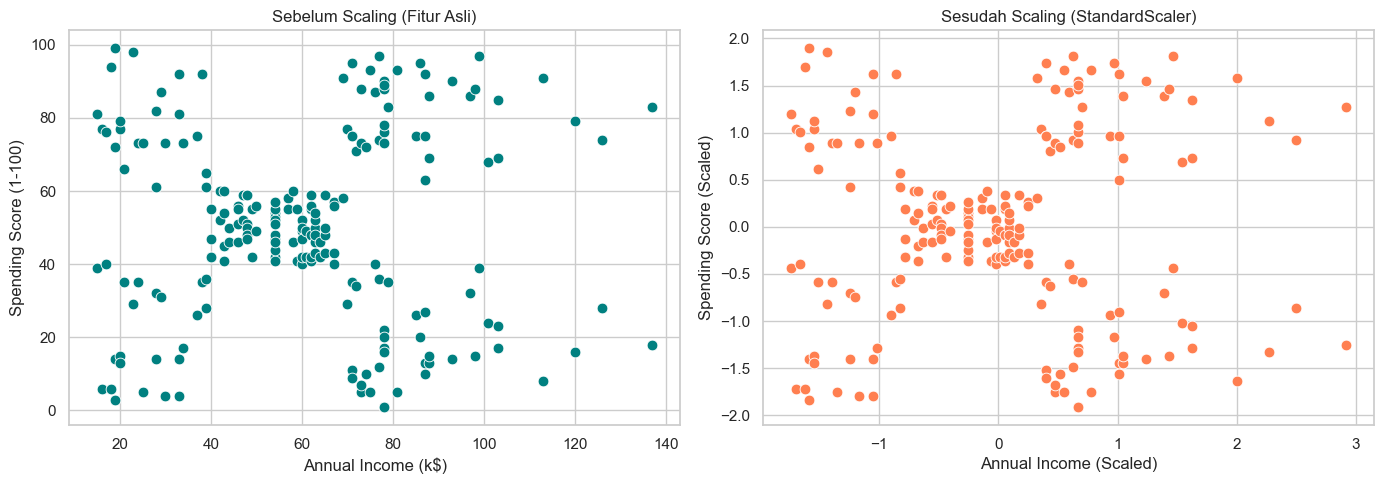

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    ax=axes[0],
    color="teal",
    s=60,
)
axes[0].set_title("Sebelum Scaling (Fitur Asli)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True)

sns.scatterplot(
    data=X_scaled,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    ax=axes[1],
    color="coral",
    s=60,
)
axes[1].set_title("Sesudah Scaling (StandardScaler)")
axes[1].set_xlabel("Annual Income (Scaled)")
axes[1].set_ylabel("Spending Score (Scaled)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

1. Alasan kenapa fitur ini di pilih karena kedua fitur ini memberikan kombinasi informasi perilaku ekonomi pelanggan yang saling melengkapi. Pendapatan tahunan menggambarkan daya beli pelanggan, sedangkan skor pengeluaran menggambarkan tingkat loyalitas dan kebiasaan belanja di mall. Penggunaan dua fitur ini memungkinkan visualisasi clustering secara langsung dalam ruang 2D tanpa reduksi dimensi

2. Alasan CustomerID Tidak Digunakan ksrena CustomerID hanya merupakan nomor urut identitas acak yang diberikan sistem saat registrasi. Variabel ini tidak mengandung atribut kuantitatif atau pola perilaku pelanggan, sehingga menyertakannya ke dalam perhitungan jarak akan merusak struktur cluster alami data

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [146]:
dbscan_base = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan_base.fit_predict(X_scaled)

print("Pelatihan DBSCAN baseline selesai.")

Pelatihan DBSCAN baseline selesai.


In [147]:
label_counts = pd.Series(labels_dbscan).value_counts().sort_index()

n_clusters_base = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_base = list(labels_dbscan).count(-1)

print("Jumlah anggota setiap label:")
display(label_counts)

print(f"\nJumlah cluster (tanpa noise): {n_clusters_base}")
print(f"Jumlah titik noise (label -1): {n_noise_base}")

Jumlah anggota setiap label:


-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


Jumlah cluster (tanpa noise): 7
Jumlah titik noise (label -1): 35


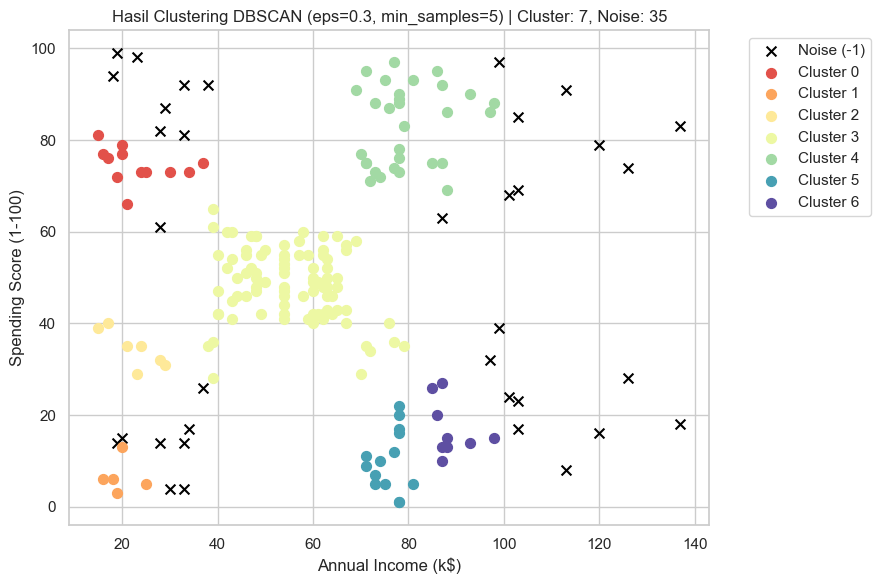

In [148]:
plt.figure(figsize=(9, 6))

unique_labels = sorted(set(labels_dbscan))
colors = [
    plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))
]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]

    class_member_mask = labels_dbscan == k
    xy = X[class_member_mask]

    if k == -1:
        plt.scatter(
            xy.iloc[:, 0],
            xy.iloc[:, 1],
            c=[col],
            marker="x",
            s=50,
            label="Noise (-1)",
        )
    else:
        plt.scatter(
            xy.iloc[:, 0],
            xy.iloc[:, 1],
            c=[col],
            marker="o",
            s=50,
            label=f"Cluster {k}",
        )

plt.title(
    f"Hasil Clustering DBSCAN (eps=0.3, min_samples=5) | Cluster: {n_clusters_base}, Noise: {n_noise_base}"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [149]:
eps_values = [0.2, 0.3, 0.35, 0.4, 0.45, 0.5]
min_samples_values = [3, 5, 7, 10]

dbscan_results = []

for eps in eps_values:
    for ms in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=ms)
        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        if n_clusters > 1:
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                sil = silhouette_score(X_scaled[mask], labels[mask])
            else:
                sil = np.nan
        else:
            sil = np.nan

        dbscan_results.append(
            {
                "eps": eps,
                "min_samples": ms,
                "jumlah_cluster": n_clusters,
                "jumlah_noise": n_noise,
                "silhouette_score": sil,
            }
        )

dbscan_summary_df = pd.DataFrame(dbscan_results)

print("Tabel Ringkasan Eksperimen Parameter DBSCAN:")
display(dbscan_summary_df)

Tabel Ringkasan Eksperimen Parameter DBSCAN:


,eps,min_samples,jumlah_cluster,jumlah_noise,silhouette_score
0,0.20,3,13,44,0.469713
1,0.20,5,7,77,0.585613
2,0.20,7,4,100,0.609411
3,0.20,10,1,129,NaN
4,0.30,3,9,14,0.472040
5,0.30,5,7,35,0.524328
6,0.30,7,4,72,0.645159
7,0.30,10,4,88,0.607301
8,0.35,3,7,11,0.515389
9,0.35,5,6,23,0.557746


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?


1. Meningkatnya nilai eps memperluas jangkauan pencarian titik tetangga. Hal ini menyebabkan jumlah titik noise berkurang secara drastis karena semakin banyak titik yang dapat terjangkau oleh radius core point. Selain itu, nilai eps yang terlalu besar (misal eps = 0.5) akan menggabungkan cluster-cluster berdekatan menjadi satu atau dua cluster besar saja

2. Meningkatnya syarat min_samples memperketat kriteria suatu titik untuk menjadi core point. Kenaikan nilai min_samples menyebabkan lebih banyak titik yang gagal memenuhi syarat kerapatan sehingga jumlah titik noise bertambah, dan jumlah cluster cenderung berkurang atau terpecah menjadi kelompok yang lebih kecil

3. Kombinasi Parameter Ekstrem:
   - Kombinasi eps = 0.20 dan min_samples = 10 menghasilkan noise yang sangat tinggi yaitu 129 titik (64.5 persen dari total data) dan hanya membentuk 1 cluster
   - Kombinasi eps = 0.50 dan min_samples = 3 menggabungkan hampir seluruh titik ke dalam 2 cluster besar saja dan menyisakan 7 titik noise
   - Kombinasi yang seimbang berada pada eps = 0.35 dan min_samples = 5 yang membentuk 6 cluster dengan 23 titik noise serta Silhouette Score sebesar 0.5577 pada data non-noise

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [150]:
birch_base = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch_base.fit_predict(X_scaled)


In [151]:
label_counts_birch = pd.Series(labels_birch).value_counts().sort_index()
n_clusters_birch = len(set(labels_birch))

print("Jumlah anggota setiap cluster BIRCH:")
display(label_counts_birch)

print("\nJumlah cluster yang terbentuk:", n_clusters_birch)

Jumlah anggota setiap cluster BIRCH:


0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64


Jumlah cluster yang terbentuk: 5


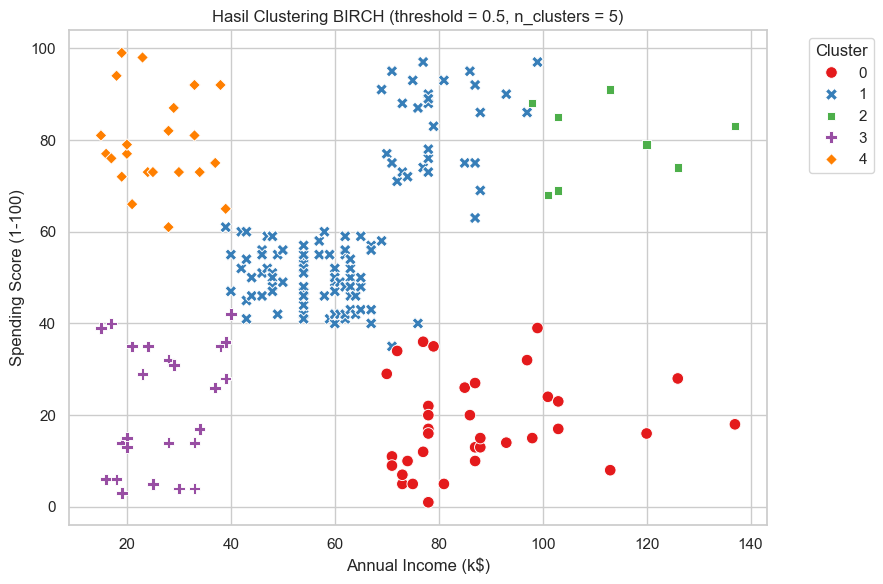

In [152]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_birch,
    palette="Set1",
    s=70,
    style=labels_birch,
)

plt.title("Hasil Clustering BIRCH (threshold = 0.5, n_clusters = 5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [153]:
thresholds = [0.3, 0.5, 0.7, 1.0]
birch_results = []

for th in thresholds:
    model = Birch(threshold=th, n_clusters=5)
    labels = model.fit_predict(X_scaled)

    n_c = len(set(labels))
    sil = silhouette_score(X_scaled, labels)

    birch_results.append(
        {"threshold": th, "jumlah_cluster": n_c, "silhouette_score": sil}
    )

birch_summary_df = pd.DataFrame(birch_results)

print("Tabel Perbandingan Parameter Threshold BIRCH:")
display(birch_summary_df)

Tabel Perbandingan Parameter Threshold BIRCH:


c:\Users\Nazwar\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,jumlah_cluster,silhouette_score
0,0.3,5,0.478062
1,0.5,5,0.414450
2,0.7,5,0.420676
3,1.0,4,0.388557


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

1. Ketika nilai threshold diperbesar, radius maksimum subcluster feature tree menjadi lebih luas. Hal ini menyebabkan titik data yang jaraknya lebih jauh dapat digabungkan ke dalam subcluster yang sama. Jika n_clusters diatur ke None, pembesaran threshold akan secara otomatis mengurangi jumlah subcluster akhir yang terbentuk. Jika threshold terlalu besar seperti threshold 1.0, jumlah subcluster awal yang terbentuk bahkan menjadi kurang dari nilai n_clusters yang ditentukan.

2. DBSCAN mendeteksi titik yang berada jauh di area berkepadatan rendah secara eksplisit dan memberinya label minus 1 sebagai noise. Sebaliknya, BIRCH tidak memiliki mekanisme pelabelan noise. BIRCH memaksa setiap titik data untuk masuk ke dalam subcluster terdekat dalam struktur pohon CF Tree, meskipun titik tersebut berada cukup jauh dari kelompok utama.

3. Parameter n_clusters pada BIRCH berfungsi sebagai langkah clustering global tahap akhir yaitu agglomerative clustering terhadap centroid subcluster yang dihasilkan oleh CF Tree. Jika n_clusters ditentukan misalnya n_clusters 5, BIRCH akan menggabungkan subcluster akhir menjadi tepat 5 kelompok utama. Jika n_clusters diatur ke None, jumlah cluster akhir akan murni ditentukan oleh nilai threshold yang membatasi ukuran radius subcluster.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [154]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)


In [155]:
label_counts_gmm = pd.Series(labels_gmm).value_counts().sort_index()

print("Jumlah anggota setiap cluster GMM:")
display(label_counts_gmm)

probs_gmm = gmm.predict_proba(X_scaled)
probs_df = pd.DataFrame(
    probs_gmm, columns=[f"Prob_Cluster_{i}" for i in range(5)]
)

print("\n5 baris pertama probabilitas keanggotaan:")
display(probs_df.head())

probs_df["Max_Probability"] = probs_gmm.max(axis=1)
uncertain_points = probs_df.sort_values("Max_Probability").head(5)

print("\n5 sampel titik dengan keanggotaan paling tidak pasti:")
display(uncertain_points)

Jumlah anggota setiap cluster GMM:


0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


5 baris pertama probabilitas keanggotaan:


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4
0,1.576897e-05,1.880092e-08,9.520312e-04,5.200131e-08,0.999032
1,1.627762e-05,1.895968e-04,9.997902e-01,4.210134e-23,0.000004
2,2.213394e-19,9.526157e-19,1.225495e-12,1.862233e-04,0.999814
3,1.054448e-04,1.800877e-04,9.996937e-01,3.793901e-21,0.000021
4,6.473014e-05,3.842732e-08,1.556695e-03,4.757227e-08,0.998378



5 sampel titik dengan keanggotaan paling tidak pasti:


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4,Max_Probability
124,0.497063,4.020399e-07,5.610367e-14,5.029323e-01,4.143026e-06,0.502932
48,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381
49,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381
27,0.278521,4.886785e-04,6.746109e-01,1.610322e-12,4.637931e-02,0.674611
160,0.772053,1.625129e-05,1.301359e-16,2.279312e-01,6.913927e-09,0.772053


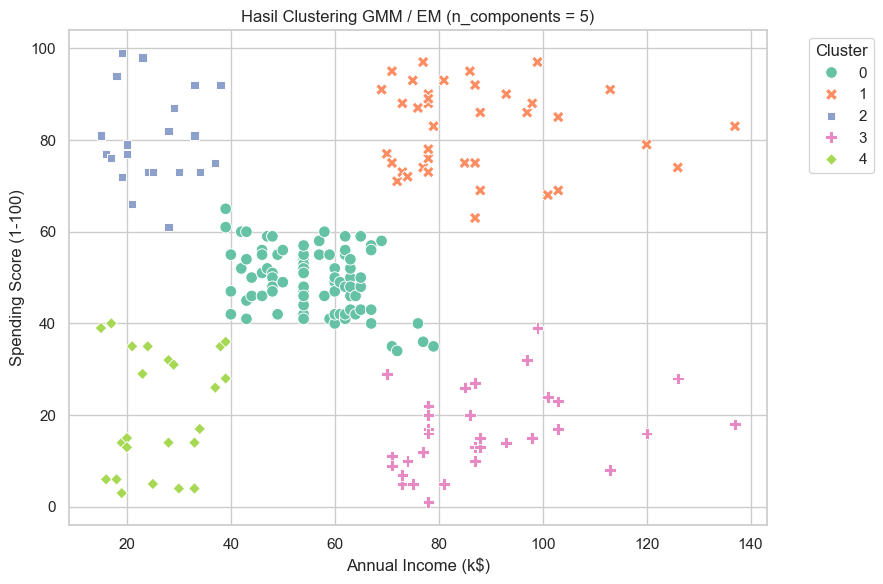

In [156]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_gmm,
    palette="Set2",
    s=70,
    style=labels_gmm,
)

plt.title("Hasil Clustering GMM / EM (n_components = 5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [157]:
n_components_range = range(2, 9)
gmm_results = []

for n in n_components_range:
    model = GaussianMixture(
        n_components=n, covariance_type="full", random_state=42
    )
    labels = model.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    bic = model.bic(X_scaled)

    gmm_results.append(
        {"n_components": n, "silhouette_score": sil, "bic_score": bic}
    )

gmm_summary_df = pd.DataFrame(gmm_results)

print("Tabel Komparasi Parameter n_components GMM:")
display(gmm_summary_df)

Tabel Komparasi Parameter n_components GMM:


,n_components,silhouette_score,bic_score
0,2,0.379082,1153.904655
1,3,0.430190,1151.718274
2,4,0.413392,1103.790149
3,5,0.553689,1058.652252
4,6,0.516982,1074.682807
5,7,0.509057,1087.328517
6,8,0.430210,1102.370701


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

1. Probabilitas keanggotaan mewakili tingkat kepastian atau derajat keanggotaan soft clustering suatu titik data terhadap setiap komponen distribusi Gaussian. Berbeda dari hard clustering seperti K-Means atau DBSCAN yang langsung menetapkan satu label pasti, GMM memberikan nilai probabilitas antara 0 hingga 1 untuk seluruh komponen. Nilai probabilitas ini dihitung pada tahap Expectation yaitu E-Step dalam algoritma EM.

2. Mengubah nilai n_components memengaruhi jumlah distribusi Gaussian campuran yang dimodelkan. Jika n_components terlalu kecil seperti n_components 2 atau 3, model akan menggabungkan kelompok kelompok data yang terpisah secara visual sehingga nilai Silhouette Score menjadi rendah. Jika n_components disetel ke 5, model berhasil menangkap 5 struktur kelompok alami pada data secara presisi.

3. GMM memerlukan penentuan n_components di awal karena algoritma EM bekerja dengan mengestimasi parameter statistik seperti vektor rata rata mean, matriks kovarians, dan bobot pencampuran campuran untuk sejumlah K distribusi Gaussian tertentu. Tanpa menetapkan nilai K di awal, algoritma tidak dapat menginisialisasi ukuran matriks parameter yang akan dioptimalkan secara iteratif.

4. Pada dataset ini, model dengan n_components 5 menghasilkan nilai Silhouette Score tertinggi yaitu 0.5537 sekaligus memiliki nilai BIC terendah yaitu 1058.65. Hal ini menunjukkan bahwa n_components 5 tidak hanya memberikan pemisahan cluster yang paling tegas secara geometris, tetapi juga merupakan model probabilistik yang paling optimal dan efisien menurut kriteria statistik BIC tanpa mengalami overfitting.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [158]:
def evaluate_clustering(X_data, labels, model_name):
    unique_labels = set(labels)
    n_noise = list(labels).count(-1)

    if -1 in unique_labels:
        mask = labels != -1
        eval_X = X_data[mask]
        eval_labels = labels[mask]
        n_clusters = len(set(eval_labels))
    else:
        eval_X = X_data
        eval_labels = labels
        n_clusters = len(set(eval_labels))

    if n_clusters >= 2 and n_clusters < len(eval_X):
        sil = silhouette_score(eval_X, eval_labels)
        db = davies_bouldin_score(eval_X, eval_labels)
        ch = calinski_harabasz_score(eval_X, eval_labels)
    else:
        sil, db, ch = np.nan, np.nan, np.nan

    return {
        "model": model_name,
        "jumlah_cluster": n_clusters,
        "jumlah_noise": n_noise if -1 in unique_labels else 0,
        "silhouette_score": sil,
        "davies_bouldin_index": db,
        "calinski_harabasz_score": ch,
    }

In [159]:
res_dbscan = evaluate_clustering(
    X_scaled, labels_dbscan, "DBSCAN (eps=0.35, min_samples=5)"
)
res_birch = evaluate_clustering(
    X_scaled, labels_birch, "BIRCH (threshold=0.3, n_clusters=5)"
)
res_gmm = evaluate_clustering(
    X_scaled, labels_gmm, "GMM / EM (n_components=5)"
)

comparison_metrics_df = pd.DataFrame([res_dbscan, res_birch, res_gmm])

print("Tabel Evaluasi Ringkasan Model Terbaik:")
display(comparison_metrics_df)

Tabel Evaluasi Ringkasan Model Terbaik:


,model,jumlah_cluster,jumlah_noise,silhouette_score,davies_bouldin_index,calinski_harabasz_score
0,"DBSCAN (eps=0.35, min_samples=5)",7,35,0.524328,0.579955,185.575811
1,"BIRCH (threshold=0.3, n_clusters=5)",5,0,0.414450,0.697938,125.948605
2,GMM / EM (n_components=5),5,0,0.553689,0.576010,244.940197


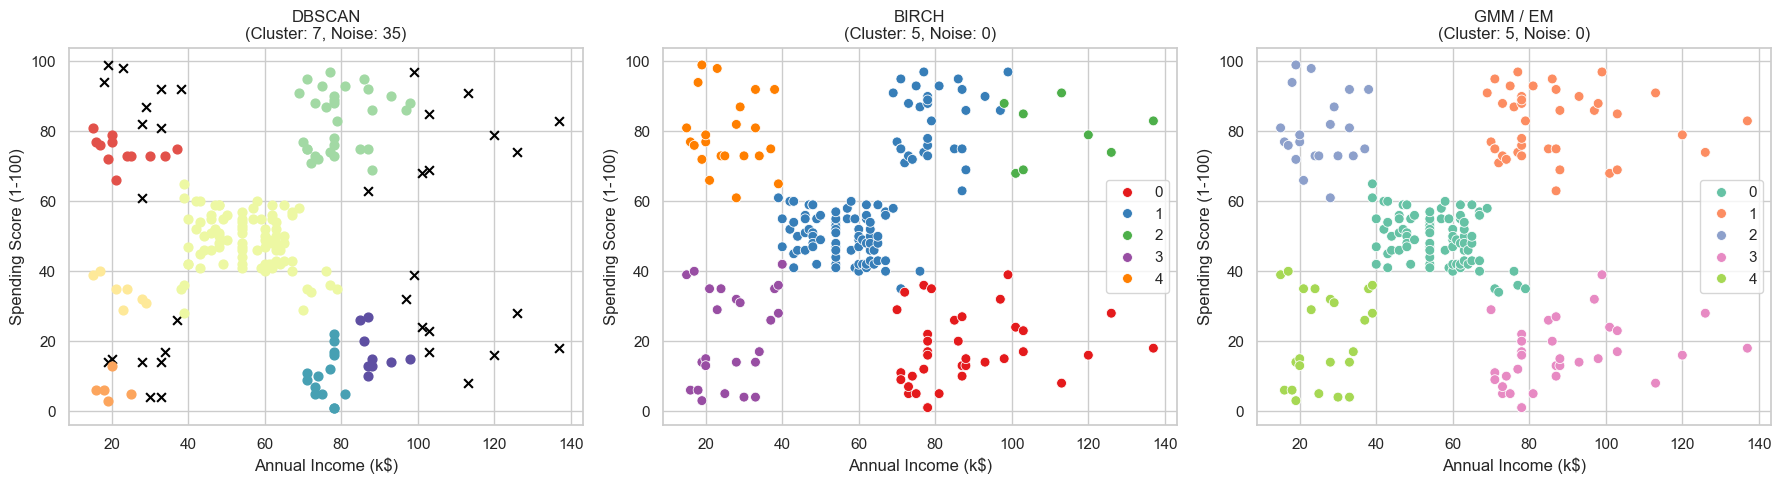

In [160]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

unique_db = sorted(set(labels_dbscan))
colors_db = [
    plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_db))
]

for k, col in zip(unique_db, colors_db):
    if k == -1:
        col = [0, 0, 0, 1]
    mask = labels_dbscan == k
    xy = X[mask]
    if k == -1:
        axes[0].scatter(
            xy.iloc[:, 0],
            xy.iloc[:, 1],
            c=[col],
            marker="x",
            s=40,
            label="Noise (-1)",
        )
    else:
        axes[0].scatter(
            xy.iloc[:, 0],
            xy.iloc[:, 1],
            c=[col],
            marker="o",
            s=40,
            label=f"Cluster {k}",
        )

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = list(labels_dbscan).count(-1)
axes[0].set_title(f"DBSCAN\n(Cluster: {n_clusters_db}, Noise: {n_noise_db})")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True)

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_birch,
    palette="Set1",
    s=50,
    ax=axes[1],
)
axes[1].set_title(f"BIRCH\n(Cluster: {len(set(labels_birch))}, Noise: 0)")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].grid(True)

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_gmm,
    palette="Set2",
    s=50,
    ax=axes[2],
)
axes[2].set_title(f"GMM / EM\n(Cluster: {len(set(labels_gmm))}, Noise: 0)")
axes[2].set_xlabel("Annual Income (k$)")
axes[2].set_ylabel("Spending Score (1-100)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [161]:
df["DBSCAN_Cluster"] = labels_dbscan
df["BIRCH_Cluster"] = labels_birch
df["GMM_Cluster"] = labels_gmm

print("=== PROFIL CLUSTER DBSCAN ===")
db_profile = df.groupby("DBSCAN_Cluster")[features].agg(
    ["count", "median", "mean"]
)
display(db_profile)

print("\n=== PROFIL CLUSTER BIRCH ===")
birch_profile = df.groupby("BIRCH_Cluster")[features].agg(
    ["count", "median", "mean"]
)
display(birch_profile)

print("\n=== PROFIL CLUSTER GMM ===")
gmm_profile = df.groupby("GMM_Cluster")[features].agg(
    ["count", "median", "mean"]
)
display(gmm_profile)

=== PROFIL CLUSTER DBSCAN ===


Annual Income (k$)                   Spending Score (1-100)  \
                            count median       mean                  count   
DBSCAN_Cluster                                                               
-1                             35   87.0  70.600000                     35   
 0                             12   20.5  23.166667                     12   
 1                              5   19.0  19.600000                      5   
 2                              7   23.0  22.428571                      7   
 3                             88   54.0  55.227273                     88   
 4                             30   78.0  79.533333                     30   
 5                             14   77.5  75.928571                     14   
 6                              9   87.0  88.777778                      9   

                                  
               median       mean  
DBSCAN_Cluster                    
-1               61.0  51.657143  
 0               74.0  74.583333  
 1                6.0   6.600000  
 2               35.0  34.428571  
 3               49.0  48.579545  
 4               86.0  83.133333  
 5                9.5  10.071429  
 6               15.0  17.000000


=== PROFIL CLUSTER BIRCH ===


Annual Income (k$)                    Spending Score (1-100)  \
                           count median        mean                  count   
BIRCH_Cluster                                                                
0                             36   83.0   87.750000                     36   
1                            109   62.0   62.394495                    109   
2                              8  108.0  112.625000                      8   
3                             25   28.0   27.400000                     25   
4                             22   24.5   25.727273                     22   

                                 
              median       mean  
BIRCH_Cluster                    
0               16.0  17.583333  
1               55.0  59.256881  
2               81.0  79.625000  
3               26.0  22.600000  
4               77.0  79.363636


=== PROFIL CLUSTER GMM ===


Annual Income (k$)                   Spending Score (1-100)  \
                         count median       mean                  count   
GMM_Cluster                                                               
0                           84   55.5  55.642857                     84   
1                           39   79.0  86.538462                     39   
2                           21   24.0  25.095238                     21   
3                           33   86.0  88.818182                     33   
4                           23   25.0  26.304348                     23   

                               
            median       mean  
GMM_Cluster                    
0             49.5  49.369048  
1             83.0  82.128205  
2             77.0  80.047619  
3             15.0  16.000000  
4             17.0  20.913043

### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional (Tidak jika n_clusters disetel ke None, Ya jika ditentukan) | Ya |
| Dapat memberi label noise secara eksplisit? | Ya (diberi label minus 1) | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | eps dan min_samples | threshold dan n_clusters | n_components dan covariance_type |
| Bentuk cluster yang dapat dimodelkan | Arbitrari / tidak beraturan berdasarkan kerapatan | Sferis / bulat | Elips dan sferis fleksibel berdasarkan matriks kovarians |
| Kelebihan | Mampu mendeteksi noise dan menemukan cluster berbentuk tidak beraturan tanpa menentukan jumlah cluster di awal | Sangat efisien dalam penggunaan memori dan waktu komputasi untuk merangkum data berukuran besar | Menyediakan probabilitas keanggotaan soft clustering dan sangat fleksibel dalam memodelkan bentuk cluster elips |
| Kekurangan | Sensitif terhadap penentuan nilai eps serta kesulitan jika kerapatan antar cluster bervariasi | Sensitif terhadap urutan masukan data dan tidak membuang outlier secara eksplisit | Sensitif terhadap inisialisasi awal serta rentang jebakan local optima jika asumsi distribusi Gaussian tidak terpenuhi |

# 7. Analisis


1. Pentingnya Scaling Fitur Sebelum Clustering:
Scaling fitur menggunakan StandardScaler sangat krusial karena algoritma clustering seperti DBSCAN, BIRCH, dan GMM mengandalkan perhitungan jarak Euclidean atau estimasi distribusi statistik. Dalam dataset ini, variabel Annual Income dan Spending Score memiliki skala dan satuan yang berbeda. Tanpa scaling, fitur dengan rentang nilai atau varians yang lebih besar akan mendominasi perhitungan jarak, sehingga membiaskan bentuk cluster yang terbentuk. Scaling mengubah kedua fitur agar memiliki rata-rata 0 dan standar deviasi 1 sehingga setiap variabel berkontribusi secara seimbang.

2. Pengaruh Perubahan Parameter DBSCAN:
Meningkatnya nilai eps memperluas radius pencarian tetangga sehingga jumlah titik noise berkurang dan cluster-cluster berdekatan cenderung menyatu. Sebaliknya, meningkatnya min_samples memperketat kriteria core point sehingga jumlah titik noise bertambah dan jumlah cluster cenderung berkurang. Pada eksperimen, eps 0.35 dan min_samples 5 memberikan keseimbangan terbaik dengan membentuk 6 cluster dan 23 titik noise dengan Silhouette Score sebesar 0.5577.

3. Pengaruh Parameter threshold dan n_clusters pada BIRCH:
Parameter threshold mengatur radius maksimum subcluster dalam struktur pohon CF Tree. Pembesaran nilai threshold menyebabkan subcluster yang terbentuk menjadi lebih besar dan jumlah subcluster awal berkurang. Sementara itu, n_clusters mengontrol jumlah kelompok akhir melalui clustering hierarki global pada centroid subcluster. Kombinasi threshold 0.3 dan n_clusters 5 terbukti optimal dalam menghasilkan 5 kelompok yang terpisah secara rapi.

4. Makna Probabilitas Keanggotaan GMM dan Peran Algoritma EM:
Probabilitas keanggotaan pada GMM mencerminkan derajat kepastian suatu titik data milik masing-masing distribusi Gaussian (soft clustering). Algoritma EM memanfaatkan probabilitas ini melalui dua tahap utama:
- E-Step (Expectation): Menghitung probabilitas keanggotaan posterior setiap titik data untuk seluruh komponen berdasarkan parameter model saat ini.
- M-Step (Maximization): Memperbarui parameter model yaitu mean, matriks kovarians, dan bobot campuran dengan memaksimalkan fungsi likelihood berdasarkan probabilitas keanggotaan yang dihitung pada E-Step.

5. Kemudahan Interpretasi Model:
Model GMM dan BIRCH dengan 5 cluster merupakan model yang paling mudah diinterpretasikan pada dataset ini. Hal ini disebabkan karena pemisahan 5 kelompok pelanggan secara visual sangat selaras dengan pola sebaran alami data pada scatter plot 2D antara Annual Income dan Spending Score. Sebaliknya, DBSCAN memisahkan salah satu kelompok utama menjadi dua sub-cluster kecil dan membuang 23 titik data sebagai noise sehingga sedikit lebih sulit diinterpretasikan secara bisnis.

6. Konsistensi Metrik Evaluasi:
Metrik evaluasi internal menunjukkan konsistensi yang tinggi antara GMM dan DBSCAN pada data non-noise. GMM (n_components 5) memperoleh Silhouette Score sebesar 0.5537, Davies-Bouldin Index sebesar 0.5760, dan Calinski-Harabasz Score sebesar 244.94. DBSCAN (eps 0.35, min_samples 5) pada titik non-noise memperoleh Silhouette Score sebesar 0.5577 dan Davies-Bouldin Index sebesar 0.5106. BIRCH memiliki performa metrik sedikit lebih rendah (Silhouette Score 0.4781) karena batasan struktur sferis CF Tree.

7. Karakteristik dan Penamaan Deskriptif Cluster (Berdasarkan Median GMM / BIRCH):
- Cluster 1 - High Income, High Spending (Target Utama / Priority Customers): Median pendapatan 79k USD dan median skor pengeluaran 83. Pelanggan kaya yang sangat aktif berbelanja.
- Cluster 2 - High Income, Low Spending (Pelanggan Hemat / Frugal Customers): Median pendapatan 86k USD dan median skor pengeluaran 15. Pelanggan berpenghasilan tinggi yang selektif dalam pengeluaran.
- Cluster 3 - Medium Income, Medium Spending (Pelanggan Rata-rata / Average Customers): Median pendapatan 55.5k USD dan median skor pengeluaran 49.5. Kelompok terbesar yang berada di kelas menengah.
- Cluster 4 - Low Income, High Spending (Pelanggan Impulsif / Careless Customers): Median pendapatan 24k USD dan median skor pengeluaran 77. Pelanggan berpendapatan rendah namun memiliki konsumsi tinggi.
- Cluster 5 - Low Income, Low Spending (Pelanggan Sensitif Harga / Sensible Customers): Median pendapatan 25k USD dan median skor pengeluaran 17. Pelanggan berpendapatan rendah dengan konsumsi minimal.

8. Keterbatasan Dua Fitur dan Dataset Ukuran Kecil:
Penggunaan hanya dua fitur membatasi pemahaman terhadap aspek profil pelanggan lainnya seperti usia, jenis kelamin, frekuensi kunjungan, atau kategori produk yang dibeli. Selain itu, ukuran dataset yang kecil (200 baris) membuat estimasi parameter statistik seperti matriks kovarians pada GMM atau kriteria kepadatan pada DBSCAN lebih rentan terhadap variasi sampel lokal.

# 8. Kesimpulan dan Saran

- Algoritma Paling Berguna: Gaussian Mixture Model (GMM) memberikan hasil paling berguna dan seimbang untuk dataset ini. GMM berhasil menangkap 5 struktur cluster alami secara presisi tanpa membuang titik data sebagai noise, serta mencatatkan Silhouette Score dan kriteria BIC paling optimal.
- Parameter Pilihan:
  - GMM: n_components 5 dan covariance_type full, karena mampu memodelkan matriks kovarians elips yang fleksibel dan menghasilkan BIC terendah (1058.65).
  - DBSCAN: eps 0.35 dan min_samples 5, karena membentuk 6 cluster utama dengan jumlah noise terukur (23 titik).
  - BIRCH: threshold 0.3 dan n_clusters 5, karena membagi ruang fitur secara proporsional.
- Perbedaan Utama Algoritma:
  - DBSCAN bekerja berdasarkan kerapatan lokal dan unggul dalam mendeteksi noise serta cluster tidak beraturan tanpa menentukan jumlah cluster di awal.
  - BIRCH merangkum data ke dalam struktur CF Tree yang sangat efisien untuk dataset besar namun membatasi bentuk cluster menjadi sferis.
  - GMM/EM bekerja secara probabilistik (soft clustering) dengan mengasumsikan data berasal dari campuran distribusi Gaussian sehingga sangat fleksibel untuk pemodelan kelompok berbentuk elips.
- Eksperimen Lanjutan:
  - Memasukkan fitur Age dan Gender menggunakan teknik encoding yang sesuai atau algoritma K-Prototypes / GMM multivariat.
  - Menguji algoritma clustering lain seperti Hierarchical Agglomerative Clustering atau K-Means sebagai pembanding kuesioner.
  - Menerapkan teknik reduksi dimensi seperti PCA atau t-SNE jika jumlah fitur diperluas di masa mendatang.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)